# 03 · Modelo de clustering: K-Means

Ya tenemos a cada cliente convertido en una fila de números (la matriz `X` del reto 2). Ahora toca agruparlos.

Lo que pide el reto es:

1. Ejecutar K-Means para un rango de valores de k (el número de clusters).
2. Usar el método del codo para elegir el k.
3. Calcular el silhouette para cada k.
4. Entrenar el modelo final con el k elegido.
5. Ver cómo se reparten los clientes entre los clusters.

Además de eso, aprovechamos este notebook para cerrar dos decisiones que dejamos abiertas en el reto 2 (si la telemetría y la población ayudan o no), y para comprobar que el k que elegimos da siempre el mismo resultado.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples

from src import config, clean, clustering
from src import pipeline as pl

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
FIG = config.FIG_DIR  # todas las figuras se guardan en outputs/figuras
FIG.mkdir(parents=True, exist_ok=True)

## 1. Cómo funciona K-Means (en corto)

K-Means busca **k puntos centrales** (centroides) y asigna cada cliente al más cercano. Lo hace repitiendo dos pasos hasta que nada cambia:

1. Cada cliente se va al centroide que tiene más cerca.
2. Cada centroide se mueve al punto medio de los clientes que le han tocado.

Al final, cada cluster es un grupo de clientes que se parecen entre sí (están cerca en las 28 dimensiones de `X`) y se parecen poco a los de otros clusters.

Tres cosas que hay que saber para entender lo que viene:

- **Hay que decirle k.** El algoritmo no sabe cuántos grupos hay; eso lo decidimos nosotros, y es casi todo el trabajo de este notebook.
- **El resultado depende de por dónde empiece.** Los centroides iniciales se colocan al azar, y según dónde caigan el resultado puede cambiar. Por eso usamos `n_init=10` (lo prueba 10 veces y se queda con el mejor) y fijamos la semilla (`random_state=42`) para que nos salga lo mismo a los tres.
- **Inercia:** es la suma de las distancias al cuadrado de cada cliente a su centroide. Cuanto más baja, más apretados están los grupos. Pero ojo: siempre baja al subir k (con un cluster por cliente sería 0), así que no sirve sola para elegir.

## 2. Los datos

Partimos de la tabla de clientes y la pasamos por el pipeline del reto 2. Es el mismo pipeline, así que todo lo que decidimos allí (logaritmos, recortes, escalado, one-hot) se aplica igual.

In [2]:
if config.CLIENTS_PKL.exists():
    clientes = clean.load_clients()
else:
    clientes = clean.build_client_table(clean.load_raw())
clientes.shape

(173456, 32)

## 3. Antes de elegir k: ¿qué features usamos?

En el reto 2 dejamos dos preguntas pendientes:

- **La telemetría** la dejamos fuera del modelo base porque falta en el 40 % de los clientes. ¿Mejoraría el modelo si la metemos?
- **La población** la metimos, pero dijimos que si no aportaba la quitaríamos.

Para responderlas hacemos el barrido completo de k (de 2 a 12) con tres versiones de `X`:

| Versión | Qué lleva |
|---|---|
| **A · Reto 2** | Las features tal como salieron del reto 2, población incluida |
| **B · A + telemetría** | Lo mismo, más distancia, velocidad, consumo y horas de uso |
| **C · A − población** | Lo mismo que A, pero sin la población |

Para comparar usamos el **silhouette**, que explicamos con calma en la sección 5. Por ahora basta con saber que va de -1 a 1 y que cuanto más alto, mejor separados están los grupos.

`clustering.k_sweep` entrena un K-Means para cada k y guarda sus métricas. Cada versión tarda unos 30 segundos.

In [3]:
versiones = {
    "A · Reto 2 (con población)": pl.build_preprocessor(population=True),
    "B · A + telemetría": pl.build_preprocessor(population=True, telemetry=True),
    "C · A − población": pl.build_preprocessor(),
}
barridos = {}
for nombre, prep in versiones.items():
    X_v = prep.fit_transform(clientes)
    barridos[nombre] = clustering.k_sweep(X_v)
    print(f"{nombre}: {X_v.shape[1]} features")

A · Reto 2 (con población): 29 features


B · A + telemetría: 33 features


C · A − población: 28 features


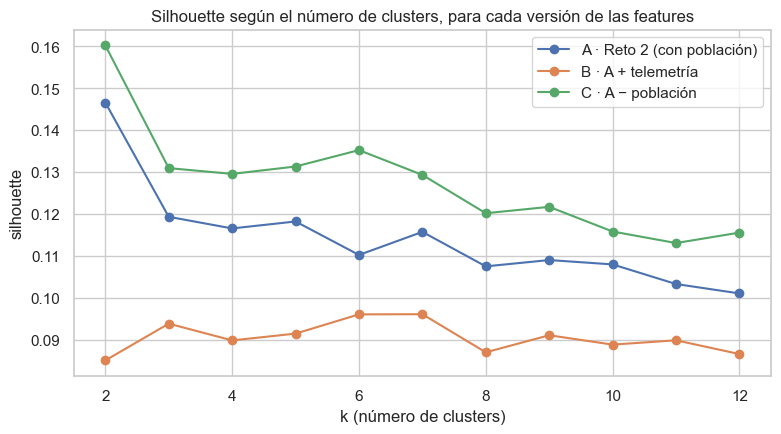

,A · Reto 2 (con población),B · A + telemetría,C · A − población
k,,,
2,0.147,0.085,0.160
3,0.119,0.094,0.131
4,0.117,0.090,0.130
5,0.118,0.091,0.131
6,0.110,0.096,0.135
7,0.116,0.096,0.129
8,0.107,0.087,0.120
9,0.109,0.091,0.122
10,0.108,0.089,0.116


In [4]:
comparativa = pd.DataFrame({nombre: b.silhouette for nombre, b in barridos.items()})

ax = comparativa.plot(marker="o", figsize=(9, 4.5))
ax.set_xlabel("k (número de clusters)")
ax.set_ylabel("silhouette")
ax.set_title("Silhouette según el número de clusters, para cada versión de las features")
plt.savefig(FIG / "03_silhouette_versiones.png", dpi=150, bbox_inches="tight")
plt.show()

comparativa.round(3)

El resultado es bastante claro:

- **La telemetría (B) empeora el modelo en todos los k.** Es lo que esperábamos en el reto 2: al rellenar con la mediana al 40 % de clientes que no la tienen, los metemos a todos en el mismo punto y los grupos se emborronan. Se queda fuera, como flag (`has_telemetry`) y para describir segmentos.
- **Quitar la población (C) mejora el modelo en todos los k.** Tiene sentido: la población casi no se relaciona con ninguna otra variable (como mucho 0,16, lo vimos en el reto 2), así que lo que hace es añadir dispersión dentro de cada grupo sin ayudar a separarlos. Como acordamos, la quitamos.

Un aviso honesto: comparar silhouettes entre versiones con distintas features no es una comparación perfecta, porque cada versión mide distancias en un espacio diferente. Pero cuando una versión gana en los 11 valores de k, la conclusión es bastante sólida.

**A partir de aquí trabajamos con la versión C**, que es la que queda por defecto en `src/pipeline.py`.

In [5]:
prep = pl.build_preprocessor()
X = prep.fit_transform(clientes)
nombres = prep.get_feature_names_out()
barrido = barridos["C · A − población"]
print("X:", X.shape)

X: (173456, 28)


### Antes de agrupar: ¿hay variables que digan lo mismo?

K-Means mide distancias, así que si dos variables están muy correlacionadas es como contar dos veces la misma idea: esa idea pesa el doble en los grupos sin que lo hayamos decidido. En el reto 2 ya quitamos las redundancias que vimos (`fleet_age_mean`, `has_current_vehicle`, el poder adquisitivo en bruto y, aquí arriba, la población). Ahora lo comprobamos sobre las 28 columnas que van de verdad al modelo, ya transformadas.

In [ ]:
corr = pd.DataFrame(X, columns=nombres).corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.3,
            cbar_kws={"label": "correlación de Pearson", "shrink": 0.7}, ax=ax)
ax.set_title("Correlación entre las 28 variables del modelo final")
plt.tight_layout()
plt.savefig(FIG / "03_correlacion_features.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Parejas con |r| >= 0,5, marcando si son columnas one-hot de la misma variable
grupos_onehot = ["main_class_group_", "main_engine_", "finance_leasing_status_"]
grupo = lambda n: next((g for g in grupos_onehot if n.startswith(g)), n)

pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().rename("r").rename_axis(["variable 1", "variable 2"]).reset_index())
pares["misma variable (one-hot)"] = pares["variable 1"].map(grupo) == pares["variable 2"].map(grupo)
fuertes = pares[pares.r.abs() >= 0.5]
fuertes.reindex(fuertes.r.abs().sort_values(ascending=False).index).round(2)

In [ ]:
distintas = pares[~pares["misma variable (one-hot)"]]
print(f"Correlación máxima entre variables distintas: {distintas.r.abs().max():.2f}")
assert distintas.r.abs().max() < 0.7  # si alguien añade una variable redundante, esto avisa

El mapa sale casi todo en tonos muy claros, que es justo lo que queríamos. Los azules suaves que se ven dentro de los bloques de clase, motor y leasing también son del one-hot: las categorías de una misma variable se excluyen entre sí. **Entre variables distintas ninguna pareja llega a 0,7** (la máxima es 0,63), que es el umbral a partir del cual se suele hablar de redundancia. Las pocas parejas que pasan de 0,5 tienen explicación:

- **"Leasing activo" y "nunca leasing" (−0,86)** son dos columnas one-hot de la misma variable. Un cliente está en una o en otra, así que es normal que vayan en sentido contrario. No es redundancia: es cómo funciona el one-hot.
- **`share_plugin_ev` con motor eléctrico o enchufable (≈0,6)**: la primera mira todos sus coches y la segunda solo el principal. Para la mayoría, que tiene un coche, coinciden, pero en los que tienen varios no, así que las dos aportan algo.
- **Visitas al taller y antigüedad (0,52)**: quien lleva más tiempo con la marca ha tenido más ocasiones de ir al taller. Tiene sentido y no es tan alta como para quitar una de las dos.

Con esto podemos agrupar tranquilos: cada variable aporta su propia información.

## 4. Método del codo

Pintamos la inercia para cada k. Como siempre baja, lo que buscamos es el punto donde **deja de bajar tanto**: el "codo". A partir de ahí, añadir otro cluster apenas hace los grupos más compactos, así que no compensa complicar la segmentación.

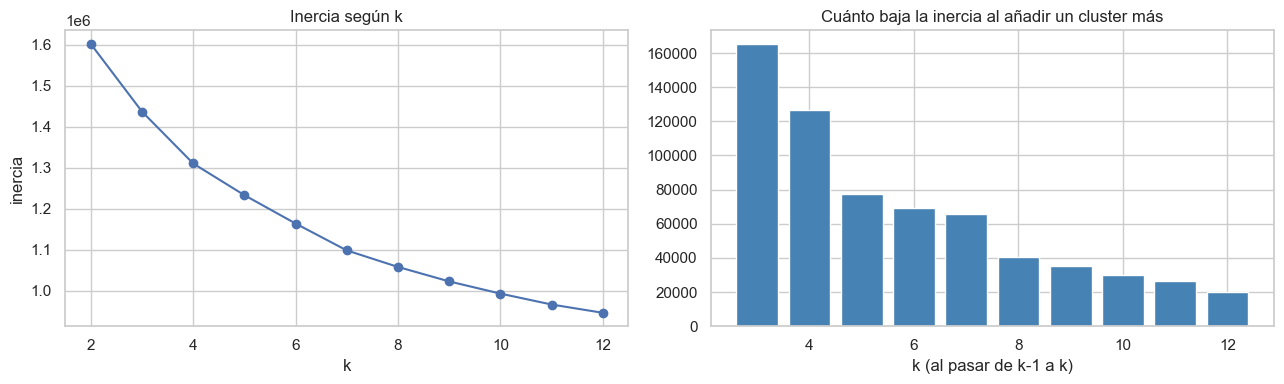

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(barrido.index, barrido.inercia, marker="o")
axes[0].set_title("Inercia según k")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inercia")

mejora = -barrido.inercia.diff()
axes[1].bar(mejora.index, mejora.values, color="steelblue")
axes[1].set_title("Cuánto baja la inercia al añadir un cluster más")
axes[1].set_xlabel("k (al pasar de k-1 a k)")

plt.tight_layout()
plt.savefig(FIG / "03_codo.png", dpi=150, bbox_inches="tight")
plt.show()

A ojo, la curva de la izquierda no tiene un codo muy marcado (es lo normal con datos reales), así que a la derecha pintamos cuánto baja la inercia cada vez que añadimos un cluster.

Ahí se ve mejor. Hay **dos escalones**: uno al pasar de 4 a 5 (la mejora baja de unas 126.000 a unas 77.000) y otro al pasar de 7 a 8 (de unas 65.000 a unas 40.000). Entre 5 y 7 la mejora se mantiene casi igual, o sea que el 6.º y el 7.º cluster todavía aportan casi tanto como el 5.º. A partir del 8.º ya no compensa.

Por eso situamos el codo en **k=7**. k=5 sería la opción más conservadora; la tendremos en cuenta al mirar el resto de criterios.

## 5. Silhouette

La inercia solo mira lo apretado que está cada grupo. El silhouette mira también **lo separado que está de los demás**. Para cada cliente se calcula:

- **a** = distancia media a los clientes de su propio cluster.
- **b** = distancia media a los clientes del cluster vecino más cercano.
- **silhouette = (b − a) / máx(a, b)**

Si sale cerca de 1, el cliente está muy metido en su grupo y lejos del resto. Cerca de 0, está en la frontera entre dos grupos. Negativo, probablemente estaría mejor en otro cluster. El silhouette del modelo es la media de todos los clientes.

Un detalle práctico: para calcularlo hay que medir la distancia de cada cliente con todos los demás. Con 173.456 clientes son unos 15.000 millones de distancias, demasiado. Así que lo calculamos sobre una **muestra de 20.000 clientes**, siempre la misma (semilla fija), para que todos los k se comparen en igualdad de condiciones.

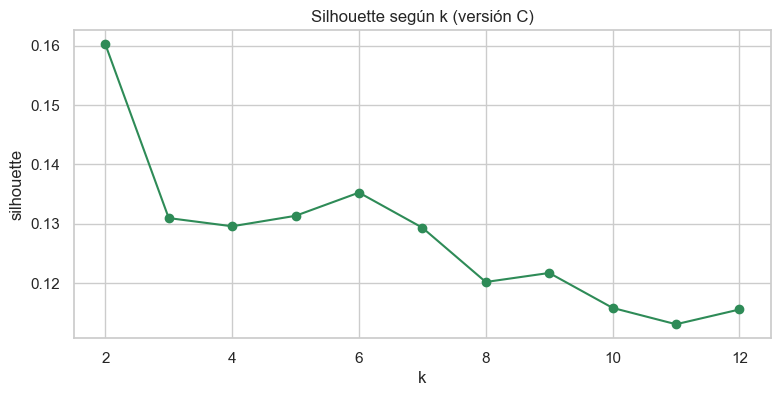

k,2,3,4,5,6,7,8,9,10,11,12
silhouette,0.16,0.131,0.13,0.131,0.135,0.129,0.12,0.122,0.116,0.113,0.116


In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(barrido.index, barrido.silhouette, marker="o", color="seagreen")
ax.set_title("Silhouette según k (versión C)")
ax.set_xlabel("k")
ax.set_ylabel("silhouette")
plt.savefig(FIG / "03_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

barrido[["silhouette"]].round(3).T

Lo primero que salta a la vista: **los valores son bajos**, entre 0,11 y 0,16. No nos asusta, y hay una explicación:

- Más de la mitad de nuestras features son binarias (one-hot y flags). Dos clientes que solo se diferencian en la clase de coche están a la misma distancia que dos que se diferencian en todo lo demás, y eso hace que las fronteras entre grupos sean poco nítidas.
- Los clientes reales no vienen en grupos perfectamente separados: hay un continuo de edades, antigüedades, etc. Lo que buscamos son **zonas con más densidad**, útiles para marketing, no islas.

En segmentación de clientes con datos mixtos, valores entre 0,1 y 0,3 son lo habitual. Lo importante es **comparar entre k**, y para eso sí nos sirve.

Leyendo la curva:

- **k=2** tiene el valor más alto, pero partir 173.000 clientes en dos grupos no sirve de mucho para marketing.
- De k=3 a k=7 se mantiene bastante plano (0,13 aprox.), con un pequeño pico en **k=6**.
- A partir de k=8 empieza a bajar.

Así que, por silhouette, cualquier k entre 3 y 7 es razonable, con k=6 ligeramente por delante. Antes de quedarnos con él, hay que mirar otra cosa.

## 6. Otras dos comprobaciones

### Davies-Bouldin y tamaño del cluster más pequeño

- **Davies-Bouldin:** compara, para cada cluster, lo disperso que está con lo lejos que está de su vecino más parecido. **Cuanto más bajo, mejor.** A diferencia del silhouette, se calcula rápido con todos los clientes.
- **Cluster más pequeño (%):** si un cluster tiene el 1 % de los clientes, para marketing es casi un nicho y suele indicar que hemos partido de más. Nos ponemos como mínimo un 3 %.

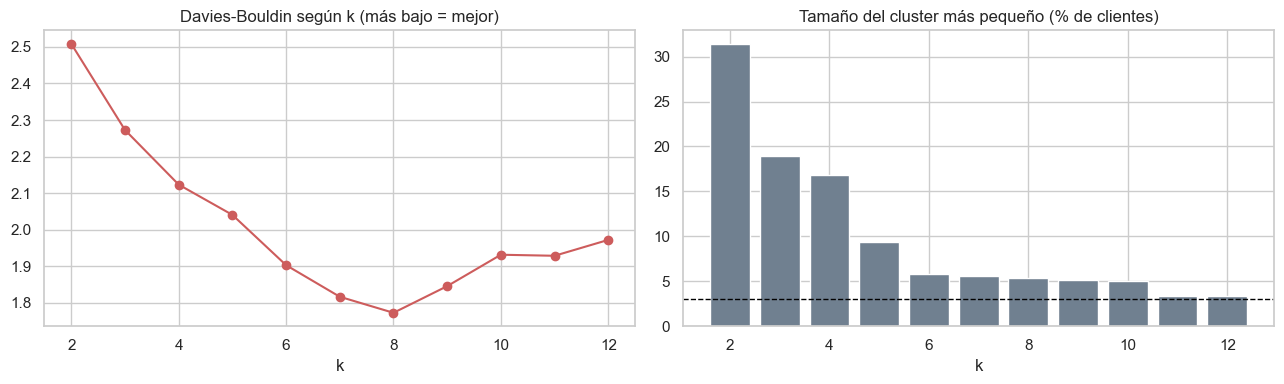

k,2,3,4,5,6,7,8,9,10,11,12
davies_bouldin,2.51,2.27,2.12,2.04,1.90,1.82,1.77,1.85,1.93,1.93,1.97
cluster_min_pct,31.35,18.94,16.79,9.33,5.84,5.59,5.34,5.15,4.99,3.41,3.39


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(barrido.index, barrido.davies_bouldin, marker="o", color="indianred")
axes[0].set_title("Davies-Bouldin según k (más bajo = mejor)")
axes[0].set_xlabel("k")
axes[1].bar(barrido.index, barrido.cluster_min_pct, color="slategray")
axes[1].axhline(3, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Tamaño del cluster más pequeño (% de clientes)")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.savefig(FIG / "03_davies_bouldin_tamano.png", dpi=150, bbox_inches="tight")
plt.show()

barrido[["davies_bouldin", "cluster_min_pct"]].round(2).T

- Davies-Bouldin baja hasta k=7-8 y luego se estanca o sube. Va en la misma línea que el codo.
- El cluster más pequeño está por encima del 3 % en todos los k, así que este criterio no descarta ninguno. Hasta k=10 ronda el 5 %.

### Estabilidad: ¿sale lo mismo con otra semilla?

Esta es la comprobación que más nos importa. Si con otra semilla (otros centroides de partida) los clusters cambian mucho, el resultado depende del azar y no de los datos, y no nos podemos fiar de él para tomar decisiones.

Para medirlo entrenamos cada k con cuatro semillas distintas y comparamos las asignaciones con el **ARI** (Adjusted Rand Index). El ARI mira, para cada par de clientes, si en los dos modelos están juntos o separados. Vale 1 si los dos modelos agrupan exactamente igual (aunque numeren los clusters distinto) y 0 si coinciden lo mismo que por azar.

In [9]:
semillas = [42, 1, 2, 3]
estabilidad = {}
for k in range(4, 10):
    etiquetas = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X) for s in semillas]
    estabilidad[k] = [adjusted_rand_score(etiquetas[0], e) for e in etiquetas[1:]]

estabilidad = pd.DataFrame(estabilidad, index=["semilla 1 vs 42", "semilla 2 vs 42", "semilla 3 vs 42"]).T
estabilidad.index.name = "k"
estabilidad.round(3)

,semilla 1 vs 42,semilla 2 vs 42,semilla 3 vs 42
k,,,
4,0.994,0.996,0.993
5,0.993,0.990,0.999
6,0.987,0.544,0.541
7,1.000,1.000,0.992
8,0.974,0.969,0.970
9,0.986,0.987,0.980


Aquí está la sorpresa: **k=6 es inestable**. Con dos de las tres semillas, el resultado solo se parece un 54 % al de la semilla 42. Es decir, con k=6 hay varias formas casi igual de buenas de partir a los clientes, y cuál sale depende de por dónde empiece el algoritmo. Su pequeño pico de silhouette no es de fiar.

En cambio, **k=7 sale prácticamente idéntico con todas las semillas** (ARI de 1,0, 1,0 y 0,99). Los demás k están por encima de 0,97.

## 7. Elegimos k = 7

Juntando todo:

| Criterio | Qué dice |
|---|---|
| Codo | Un primer escalón en k=5 y el último en k=7: a partir de ahí añadir clusters mejora muy poco |
| Silhouette | Plano entre 3 y 7 (≈0,13); k=7 está entre los mejores y a partir de 8 baja |
| Davies-Bouldin | Mejora hasta 7-8 |
| Cluster más pequeño | Por encima del 5 % con k=7 |
| Estabilidad | k=7 sale igual con todas las semillas; k=6 no |
| Negocio | 7 segmentos son manejables para un equipo de marketing (menos se quedan cortos, más son difíciles de gestionar) |

**Nos quedamos con k=7.** Está guardado en `config.K_FINAL` para que los demás notebooks usen el mismo.

## 8. El modelo final

Usamos `pl.build_pipeline()`, que encadena el preprocesado y el K-Means con k=7. Es exactamente el mismo objeto que re-entrenaremos en el Jackknife.

Un detalle: K-Means numera los clusters al azar (el "cluster 3" no significa nada). Para que los números sean estables y fáciles de seguir, los **renumeramos por tamaño**: el 0 es el más grande y el 6 el más pequeño.

In [10]:
modelo = pl.build_pipeline(config.K_FINAL)
modelo.fit(clientes)
clusters = clustering.relabel_by_size(modelo.named_steps["kmeans"].labels_)

In [11]:
reparto = pd.Series(clusters).value_counts().sort_index().to_frame("clientes")
reparto["%"] = (reparto.clientes / len(clusters) * 100).round(1)
reparto.index.name = "cluster"
reparto

,clientes,%
cluster,,
0,41811,24.1
1,31769,18.3
2,31611,18.2
3,27575,15.9
4,15660,9.0
5,15327,8.8
6,9703,5.6


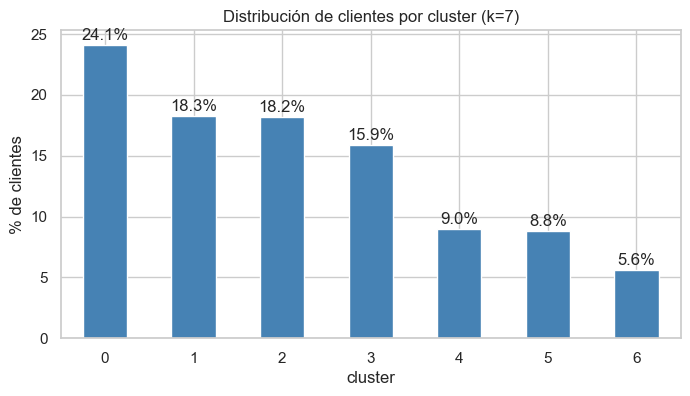

In [12]:
ax = reparto["%"].plot.bar(color="steelblue", figsize=(8, 4), rot=0)
ax.set_title(f"Distribución de clientes por cluster (k={config.K_FINAL})")
ax.set_xlabel("cluster")
ax.set_ylabel("% de clientes")
for i, v in enumerate(reparto["%"]):
    ax.text(i, v + 0.4, f"{v:.1f}%", ha="center")
plt.savefig(FIG / "03_distribucion_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

Ningún cluster es residual: van del 24 % al 5,6 % de los clientes, y el más pequeño tiene más de 9.700. Todos tienen tamaño suficiente para montarles una campaña.

### ¿Qué clusters están mejor definidos?

El silhouette medio esconde diferencias entre clusters. Lo calculamos para cada cliente de la muestra y lo promediamos por cluster:

In [13]:
idx = clustering.sample_index(len(X))
sil_clientes = silhouette_samples(X[idx], clusters[idx])
sil_cluster = pd.Series(sil_clientes).groupby(clusters[idx]).mean().round(3)
sil_cluster.index.name = "cluster"
sil_cluster.to_frame("silhouette medio")

,silhouette medio
cluster,
0,0.131
1,0.131
2,0.140
3,0.159
4,0.114
5,0.073
6,0.110


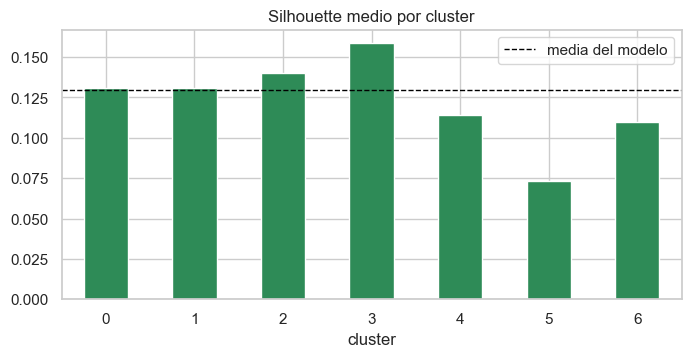

In [14]:
ax = sil_cluster.plot.bar(color="seagreen", figsize=(8, 3.5), rot=0)
ax.axhline(sil_clientes.mean(), color="black", linestyle="--", linewidth=1, label="media del modelo")
ax.set_title("Silhouette medio por cluster")
ax.legend()
plt.savefig(FIG / "03_silhouette_por_cluster.png", dpi=150, bbox_inches="tight")
plt.show()

No todos los grupos están igual de bien definidos:

- El **cluster 3** es el más nítido (0,16). Ya veremos en el vistazo de abajo que es el de los clientes con coches eléctricos o enchufables: una característica muy marcada que los separa bien del resto.
- El **cluster 5** es el más difuso (0,07). Es el de los clientes con muchos vehículos, que son un grupo más variado (desde familias con tres coches hasta flotas), así que es normal que sus fronteras sean menos claras.
- El resto está entre 0,11 y 0,14, alrededor de la media.

Esto nos lo apuntamos para el Jackknife: si algún cluster resulta inestable, el 5 es el primer sospechoso.

## 9. Un primer vistazo a los clusters

Poner nombres y montar los perfiles es el reto 4, pero queremos comprobar ya que los grupos tienen sentido. Miramos la media de algunas variables en **unidades originales** (no las escaladas, que no se entienden) y la categoría más frecuente de las categóricas:

In [15]:
vars_num = ["age_ord", "tenure_months", "ppi", "n_vehicles", "n_connected_now",
            "main_vehicle_age", "workshop_visits_mean", "share_plugin_ev", "is_ch", "tenure_is_default"]
g = clientes.assign(cluster=clusters).groupby("cluster")
vistazo = g[vars_num].mean()
vistazo.insert(0, "%", (g.size() / len(clientes) * 100))
for cat in ["main_class_group", "main_engine", "finance_leasing_status"]:
    vistazo[cat] = g[cat].agg(lambda s: f"{s.value_counts(normalize=True).index[0]} ({s.value_counts(normalize=True).iloc[0]:.0%})")
vistazo.round(2)

,%,age_ord,tenure_months,ppi,n_vehicles,n_connected_now,main_vehicle_age,workshop_visits_mean,share_plugin_ev,is_ch,tenure_is_default,main_class_group,main_engine,finance_leasing_status
cluster,,,,,,,,,,,,,,
0,24.10,2.99,47.99,47744.94,1.23,1.02,5.15,4.39,0.01,0.84,0.14,COMPACTO (40%),COMBUSTION (56%),never_active (65%)
1,18.32,2.91,17.74,42915.44,1.18,1.04,2.45,0.85,0.01,0.60,0.06,COMPACTO (37%),COMBUSTION (42%),never_active (65%)
2,18.22,2.52,32.25,41428.46,1.12,1.03,8.36,0.58,0.00,0.55,0.27,COMPACTO (36%),COMBUSTION (71%),never_active (94%)
3,15.90,3.32,29.25,42946.34,1.26,1.00,2.85,2.09,0.96,0.53,0.07,COMPACTO (37%),PLUGIN_HYBRID (51%),never_active (63%)
4,9.03,2.98,17.36,44896.21,1.27,0.00,5.63,1.18,0.16,0.64,0.01,COMPACTO (37%),COMBUSTION (51%),never_active (88%)
5,8.84,3.03,54.34,44309.72,7.18,2.24,2.26,1.82,0.23,0.61,0.09,MEDIO (27%),COMBUSTION (31%),never_active (47%)
6,5.59,3.24,39.09,91933.04,1.42,1.03,4.36,3.09,0.21,0.99,0.17,MEDIO (31%),COMBUSTION (43%),never_active (66%)


Sin ponerles nombre todavía, cada grupo tiene algo que lo distingue claramente:

- **Cluster 0 (24 %):** los más veteranos como clientes (48 meses de media), los que más van al taller (4,4 visitas por coche) y muy suizos (84 %).
- **Cluster 1 (18 %):** clientes nuevos (18 meses) con coche nuevo (2,5 años) y pocas visitas al taller.
- **Cluster 2 (18 %):** los coches más viejos (8,4 años), mucha combustión y casi nadie ha usado leasing. Además, un 27 % tiene la antigüedad por defecto de 36 meses, así que seguramente son clientes de hace más tiempo.
- **Cluster 3 (16 %):** los electrificados: el 96 % de sus coches son eléctricos o enchufables.
- **Cluster 4 (9 %):** ningún vehículo activo ahora mismo. Recoge al 87 % de los clientes que están así; son los que podríamos estar perdiendo. Un 12 % de ellos tiene además un leasing ya terminado.
- **Cluster 5 (9 %):** muchos vehículos (7 de media) y mucha antigüedad (54 meses). Aquí están casi todas las cuentas grandes.
- **Cluster 6 (6 %):** zonas muy ricas (92.000 € por habitante, el doble de la media) y casi todos en Suiza.

Fijaos en que la clase de coche (compacto o medio) casi no cambia entre grupos: lo que separa a los clientes es más su relación con la marca, la antigüedad del coche y el tipo de motor que la gama. Lo veremos con calma en el reto 4.

## 10. Guardamos las etiquetas

Guardamos el cluster de cada cliente en `outputs/labels_final.csv`. Es lo que usarán el reto 4 (perfiles), la comparativa de algoritmos y el Jackknife.

In [16]:
clustering.save_labels(clusters, clientes.index)
comprobacion = clustering.load_labels()
print("Guardado:", config.LABELS_FINAL.relative_to(config.ROOT), "|", len(comprobacion), "clientes")
assert (comprobacion.values == clusters).all()

Guardado: outputs\labels_final.csv | 173456 clientes


## 11. Resumen

- **Features:** comprobamos las dos dudas del reto 2. La telemetría empeora el modelo en todos los k y se queda fuera. La población también empeora el modelo, así que la quitamos. El modelo final usa 28 features.
- **k = 7**, elegido mirando a la vez el codo (k=7), el silhouette (plano hasta 7 y baja después), Davies-Bouldin, el tamaño mínimo de cluster y, sobre todo, la estabilidad: k=6 tenía un silhouette algo mejor pero cambia según la semilla, y k=7 sale siempre igual.
- **Silhouette ≈ 0,13:** es bajo en términos absolutos, pero normal con datos mixtos de clientes reales. Lo usamos para comparar, no como nota.
- **Reparto:** siete grupos del 24 % al 6 %, ninguno residual.
- Las etiquetas quedan en `outputs/labels_final.csv`, numeradas por tamaño.

Siguiente paso: darles nombre y perfil en el reto 4.